# Задача 2: темы диалогов

## 0. План
- 1. Выбор подхожящих диалогов, согласно EDA.
- 2. Поиграть в кластеризацию
- 3. Читаем что объединилось + обзываем
- 4. Обучаем, Кросс-валидация
- 5. Тест
- 6. Разбор ошибок

## 1. Импорты и инициализация

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

import solution_utils as su
import bur_topics_utils as tu

pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
BLUE, OCHRE = "#0072CE", "#C98A3C"

## 2. Загрузка данных (Поменяется при слиянии решений)

`dialogs` и `messages` собираются из `hw1_train.jsonl` функцией `build_frames` из `solution_utils`. `flags` — результат EDA (`dialog_flags.csv`): группы почти-копий (`group_id`), флаги шаблонов, пустых реплик и `use_topics`.

In [2]:
dialogs, messages, flags = tu.load_dialogs_and_flags()
print("dialogs:", dialogs.shape, " messages:", messages.shape, " flags:", flags.shape)

dialogs: (10001, 7)  messages: (133982, 10)  flags: (10001, 29)


## 3. Фильтры для задачи про темы

Берём правила из EDA для `flags`: 
- ~is_template` (не шаблонная первая реплика), 
- `~has_empty_message` (нет пустых реплик), 
- `use_topics` - диалоги чисто под вторую задачу.

И посмотрим сколько диалогов осталось

In [3]:
train_mask = tu.build_train_mask(flags)

In [4]:
display(tu.filter_funnel(flags))
print(f"в работе: {train_mask.sum()} из {len(flags)}")

,шаг,осталось
0,всего,10001
1,~is_template,10001
2,~has_empty_message,10001
3,use_topics,7093


в работе: 7093 из 10001


## 4. Подготовка текста диалогов

На рассмотрение будем брать весь текст пользователя. 

**Подготовка текста** (функция `preprocess_for_topics`):
1. каждая реплика обрезается до 1000 символов (огромные вставки кода мешают TF-IDF; в EDA 1% самых длинных реплик давал 8% всех символов);
2. нижний регистр, только слова из 3+ букв (числа и мусор вроде «aa», «abc» отбрасываются);
3. убираем стоп-слова
4. стемминг

**Замечание:**
Слова по типу "write", "use", "try" и остальные в этом духе - запишем в ручную в список стоп слов, т.к. тематически они ничего не значат, а встречаются очень часто,создавая шум.

In [5]:
user_text = tu.extract_user_text(messages)      # извлекаем реплики пользователя на диалог
prepared = user_text.map(tu.preprocess_for_topics)  # стоп-слова + стемминг
preview = tu.extract_preview(messages)  # исходный текст для чтения глазами

In [6]:
# пример для понимания
example_id = flags["dialog_id"].iloc[0]
print("исходный текст:\n", user_text[example_id][:300])
print("\nпосле обработки:\n", prepared[example_id][:300])

исходный текст:
 it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?
In the context of the equation “1+1=2+1+1=?,” if we want to explore the possibility of using a modulus to determine the result, we can consider different mod

после обработки:
 undefin modulus possibl concept result context equat explor possibl modulus determin result consid modulus valu affect equat modulus known remaind divid number denot symbol use remaind divis oper consid exampl modulus modulus evalu remaind divid number modulus modulus evalu remaind divid number modu


## 5. Разбиение train/test по группам "почти-копий"

Разбиваем на трейн и тест, не забывая что "братья" должны быть по одну сторону барикад, чтобы не палить модельке результаты.

In [7]:
train_ids, test_ids = tu.group_split(flags, train_mask, test_size=0.2, seed=SEED)
group_of = flags.set_index("dialog_id")["group_id"]

texts_train, texts_test = prepared.loc[train_ids], prepared.loc[test_ids]

In [8]:
print("train:", len(train_ids), " test:", len(test_ids))
print("общих групп у train и test:", len(set(group_of[train_ids]) & set(group_of[test_ids])))
print("диалогов train в группах размера > 1:", int(group_of[train_ids].duplicated(keep=False).sum()))


train: 5677  test: 1416
общих групп у train и test: 0
диалогов train в группах размера > 1: 118


## 6. Векторизация текста

**Логика.** TF-IDF даёт матрицу «диалоги × слова» с тысячами столбцов. Кластеризовать её напрямую плохо: расстояния между точками в таких пространствах почти одинаковы, а расчёт медленный. Поэтому:
1. **TF-IDF** (`sublinear_tf=True`: частота слова заменяется на `1 + ln(частота)`, чтобы повторы не доминировали);
2. **`TruncatedSVD`** сжимает до 100 столбцов — «тематических осей» (слова, которые встречаются вместе, оказываются на одной оси). Это то же сжатие, что PCA, но для разреженных матриц (обычный PCA вычитает среднее и сделал бы матрицу плотной);
3. **`Normalizer`** делает длину каждой строки равной 1: сравниваются направления, а не длины текстов.

**Замечание:** всё обучается **только на train** (`fit_transform`), а test лишь преобразуется (`transform`), чтобы информация о тесте не попала в признаки.


In [9]:
N_COMPONENTS = 100
lsa = make_pipeline(tu.make_tfidf(), TruncatedSVD(N_COMPONENTS, random_state=SEED), Normalizer(copy=False))
X_train = lsa.fit_transform(texts_train)
X_test = lsa.transform(texts_test)


In [10]:
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("словарь TF-IDF:", len(lsa[0].vocabulary_), "слов")

X_train: (5677, 100)  X_test: (1416, 100)
словарь TF-IDF: 9753 слов


## 7. Игры с кластеризацией

Два способа кластеризации, которые сравниваем:
- **KMeans на LSA:** `k` центров, каждый диалог относится к ближайшему.
- **UMAP + KMeans:** сначала UMAP сжимает 100-мерные векторы до 10 измерений, сохраняя «кто чей сосед», потом KMeans в сжатом пространстве. UMAP сам кластеры не находит, ему нужен второй шаг.

Чтобы выбрать подходящий `k`ссмотрим на две метрики:
- **inertia** — сумма квадратов расстояний до центров. Падает с ростом `k`. Ищем точку, после которой падение замедляется;
- **silhouette** — насколько диалог ближе к своему кластеру, чем к соседнему (от −1 до 1). Ищем `k`, где она велика.

**Замечание:** `silhouette_score(..., sample_size=3000)` считает силуэт по случайным 3000 точкам (на всех слишком долго). `n_init=5` — KMeans запускается 5 раз с разных стартов, берётся лучший результат.

In [11]:
reducer = umap.UMAP(n_neighbors=15, n_components=10, min_dist=0.0, random_state=SEED).fit(X_train)
U_train = reducer.embedding_    # координаты train после UMAP (10 измерений)

K_GRID = [4, 6, 8, 10, 12, 14, 16, 18, 20, 24]


def scan_k(Z):
    # Для каждого k: inertia и силуэт KMeans в пространстве Z.
    rows = []
    for k in K_GRID:
        km = KMeans(k, n_init=5, random_state=SEED).fit(Z)
        rows.append({"k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(Z, km.labels_, sample_size=3000, random_state=SEED)})
    return pd.DataFrame(rows).set_index("k")


scans = {"KMeans на LSA": scan_k(X_train), "UMAP + KMeans": scan_k(U_train)}

/home/pavel-ubunt/miniconda3/envs/ml/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


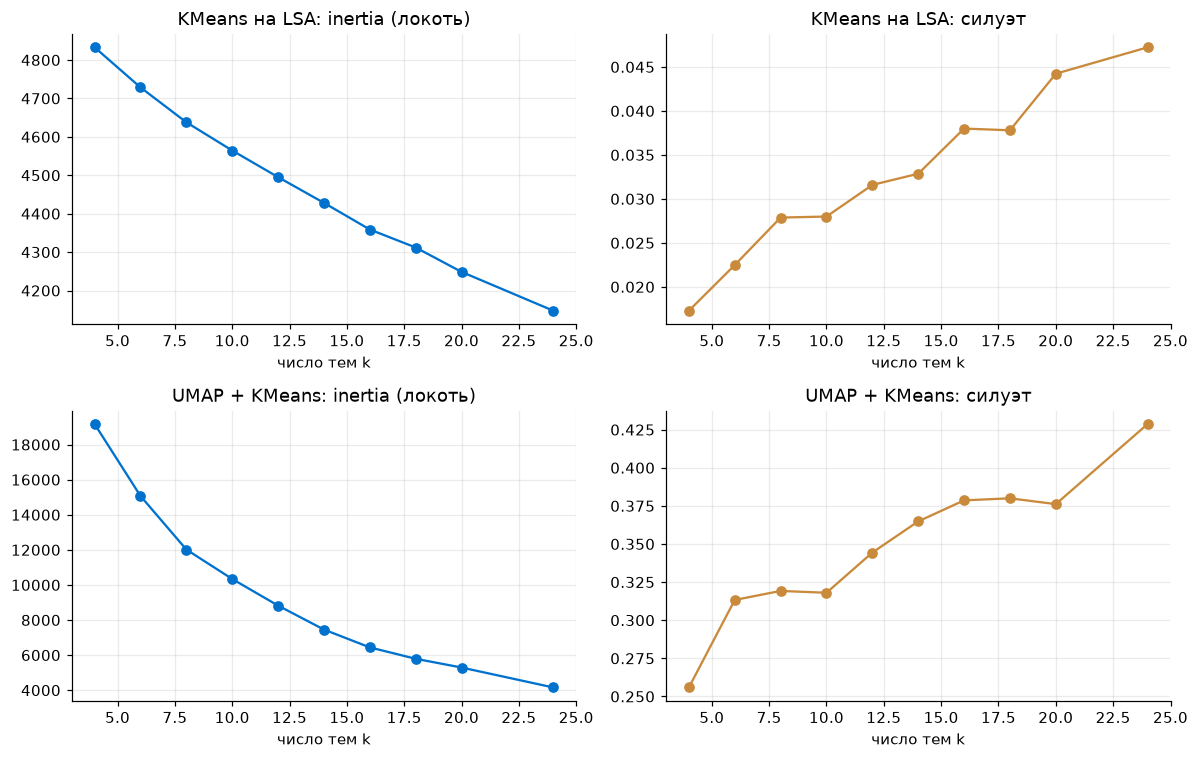

KMeans на LSA            UMAP + KMeans           
         inertia silhouette       inertia silhouette
k                                                   
4       4832.929      0.017     19167.678      0.256
6       4728.642      0.022     15068.729      0.313
8       4637.863      0.028     12015.692      0.319
10      4564.398      0.028     10337.793      0.318
12      4495.133      0.032      8821.193      0.344
14      4428.119      0.033      7454.280      0.365
16      4358.780      0.038      6438.477      0.379
18      4311.979      0.038      5789.882      0.380
20      4248.475      0.044      5291.896      0.376
24      4147.462      0.047      4154.807      0.429

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, table) in enumerate(scans.items()):
    axes[row, 0].plot(table.index, table["inertia"], "o-", color=BLUE);  axes[row, 0].set_title(f"{name}: inertia (локоть)")
    axes[row, 1].plot(table.index, table["silhouette"], "o-", color=OCHRE); axes[row, 1].set_title(f"{name}: силуэт")
    for ax in axes[row]:
        ax.set_xlabel("число тем k")
plt.tight_layout()
plt.show()
display(pd.concat(scans, axis=1).round(3))

In [13]:
N_TOPICS = 12     # выбрали по графикам

## 8. Сравнение методов и итоговые кластеры

При выбранном `N_TOPICS` строим оба разбиения и сравниваем:
- **силуэт** и **индекс Дэвиса — Болдина** (минимальный == лучший), обе оценки считаем в одном пространстве LSA, чтобы они были сопоставимы.
- **доли самой маленькой и самой большой темы** сколько от общей выборки составляет минимальная и максимальная тема;
- **ARI между методами:** 1 — одно и то же разбиение, около 0 — совсем разные.

In [14]:
km_lsa = KMeans(N_TOPICS, n_init=10, random_state=SEED).fit(X_train)
km_umap = KMeans(N_TOPICS, n_init=10, random_state=SEED).fit(U_train)
partitions = {"KMeans на LSA": km_lsa.labels_, "UMAP + KMeans": km_umap.labels_}

rows = {}
for name, labels in partitions.items():
    shares = np.bincount(labels) / len(labels)
    rows[name] = {"силуэт": silhouette_score(X_train, labels, sample_size=3000, random_state=SEED),
                  "Дэвис — Болдин": davies_bouldin_score(X_train, labels),
                  "min доля темы": shares.min(), "max доля темы": shares.max()}


In [15]:
display(pd.DataFrame(rows).T.round(3))
print("ARI между методами:", round(adjusted_rand_score(*partitions.values()), 3))

,силуэт,Дэвис — Болдин,min доля темы,max доля темы
KMeans на LSA,0.031,4.289,0.019,0.207
UMAP + KMeans,0.028,4.644,0.016,0.194


ARI между методами: 0.248


### Назад дороги нет, пора сделать выбор

In [16]:
METHOD = "KMeans на LSA"      # "KMeans на LSA" или "UMAP + KMeans"; тупо по метрикам

labels_train = partitions[METHOD]
if METHOD == "KMeans на LSA":
    labels_test = km_lsa.predict(X_test)
else:
    labels_test = km_umap.predict(reducer.transform(X_test))       # новые точки сначала проводим через UMAP

In [17]:
print("метод:", METHOD, "| диалогов по темам в train:", np.bincount(labels_train).tolist())

метод: KMeans на LSA | диалогов по темам в train: [194, 242, 407, 1177, 346, 294, 495, 732, 795, 380, 506, 109]


## 9. Читаем кластеры и называем темы

Для каждого кластера печатаем **долю**, **характерные слова** (где средний TF-IDF в кластере больше всего превышает средний вне него) и **типичные диалоги** (ближайшие к центру кластера - исходный текст первых реплик). По ним мы и даём названия в `TOPIC_NAMES`.

`|` - разделитель между репликами

In [18]:
terms = tu.distinctive_terms(texts_train, labels_train, n_terms=13) # 13 характерных слов
reps = tu.representatives(X_train, labels_train, n=5) # 5 типичных диалогов
preview_train = preview.loc[train_ids].to_numpy()

for c in range(N_TOPICS):
    print(f"━━ кластер {c} | {np.mean(labels_train == c):.1%} диалогов")
    print("   слова:", ", ".join(terms[c]))
    for i in reps[c]:
        print("   •", preview_train[i][:170])

━━ кластер 0 | 3.4% диалогов
   слова: translat, english, chines, languag, japanes, latin, french, arab, mean, text, sentenc, break, spanish
   • Translate من طريقة كلامك المبهرة وانتي طيبة جدا وشخصيتك جيده وانك نفس شخصيتي تقريبا ومثيره ايضا to English | Can you explain the streak mean | Translate ضيق to English
   • Translate to English  "そんな状況を目の前にぶるぶると肩を震わせて笑ってるまこたん。" | "　＊「めげさん、お皿を右だ、右に傾けてバランスを取って！」 ＊「そっちはひだりーーーっ！！！」  　＊「わーだめだ、崩壊する！！！」 ＊「総員退艦、退艦ーーーッ！！！」" | "ぐちゃり。"
   • “刷卡刷几百万。”Can you translate this sentence into English? | Can you make your translation more fluent? | 你是怎么活到这么大的？How to translate this into English?
   • translate 及第 | translate きゅうだい | translate from japanese 及第
   • Translate Hisztizel to English | Hungarian | Can you scale your translation capabilities on Hungarian to English?
━━ кластер 1 | 4.3% диалогов
   слова: email, thank, regard, repli, custom, request, send, receiv, confirm, updat, check, issu, order
   • How do I respond, and what do I do when Peter Lync

In [19]:
TOPIC_NAMES = {
    0:  "Общие задания творческого направления",
    1:  "Ролевые игры",
    2:  "История и политика",
    3:  "Excel и VBA",
    4:  "Спорт",
    5:  "Фанфики",
    6:  "Код",
    7:  "Учебный вайб-кодинг",
    8:  "Научная деятельность с естественными науками",
    9:  "Менеджмент и бизнес",
    10: "Как устроиться в конторку",
    11: "Перевод текстов"
}
TOPIC_DESCRIPTIONS = {
    "Общие задания творческого направления": "Запросы «общего» характера — задания по литературе, короткие упражнения, промпты для GPT, примеры и определения.",
    "Ролевые игры": "Задания по типу 'подставь себя на его место - твои действия...', 'напиши письммо от лица...'",
    "История и политика": "Запросы про исторические события, альтернативную историю, политические системы и государственное устройство. Часто с просьбой 'написать сценарий' или 'создать лор'",
    "Excel и VBA": " Работа с таблицами в Excel: написание VBA-скриптов, обработка диапазонов, отладка ошибок",
    "Спорт": "Обсуждение видеоигр, спортивных матчей, RPG-механик, чемпионатов. Смешаны игровые запросы и спортивные события",
    "Фанфики": "Запросы про написание историй, разработку персонажей, сцен и диалогов. Рассуждения про алтернативные ветки",
    "Код": "Общие вопросы по программированию: написание кода, отладка ошибок, работа с файлами, сетью, базами данных. Языки разные — Python, C#, JS",
    "Учебный вайб-кодинг": "Учебные задачки на программирование. В этом и отличие от темы 'Код'",
    "Научная деятельность с естественными науками": "Запросы по химии, физике, материаловедению. Часто с просьбой отредактировать или написать академический текст",
    "Менеджмент и бизнес": "Запросы про рынки, акции, инвестиции, новости компаний. Часты переводы или краткие сожеражания финансовых новостей",
    "Как устроиться в конторку": "Запросы на перефразирования, подбор качесвт в резюме, поиск компаний и т.д.",
    "Перевод текстов": "Запросы по переводу текстов различных"
}

name_of = {c: TOPIC_NAMES.get(c, f"тема_{c:02d}: " + ", ".join(terms[c][:3])) for c in range(N_TOPICS)}
y_train = np.array([name_of[c] for c in labels_train], dtype=object)
y_test = np.array([name_of[c] for c in labels_test], dtype=object)

topic_table = pd.DataFrame({
    "название": list(pd.Series(y_train).value_counts().index),
    "доля": pd.Series(y_train).value_counts(normalize=True).round(3).to_numpy(),
})
topic_table["описание"] = topic_table["название"].map(TOPIC_DESCRIPTIONS).fillna("")
topic_table["слова"] = topic_table["название"].map({name_of[c]: ", ".join(terms[c][:8]) for c in range(N_TOPICS)})
topic_table["пример"] = topic_table["название"].map(
    {name: preview_train[np.flatnonzero(y_train == name)[0]][:100] for name in topic_table["название"]})
print("тем:", len(topic_table))
display(topic_table)

тем: 12


,название,доля,описание,слова,пример
0,Excel и VBA,0.207,"Работа с таблицами в Excel: написание VBA-скриптов, обработка диапазонов, отладка ошибок","book, gpt, short, name, win, titl, generat, nba",write a comprehensive astrological interpretation of the sun in Aries and the moon in Virgo in a nat
1,Научная деятельность с естественными науками,0.140,"Запросы по химии, физике, материаловедению. Часто с просьбой отредактировать или написать академический текст","stori, day, feel, just, friend, episod, time, say","I am looking for an dark and horror tv show, that aired in the 90's or 2000's, which in one episode"
2,Учебный вайб-кодинг,0.129,Учебные задачки на программирование. В этом и отличие от темы 'Код',"develop, manag, student, research, learn, skill, impact, project","Make improvments by re-phrasing the following text: ""The first step in any decision-making process i"
3,Как устроиться в конторку,0.089,"Запросы на перефразирования, подбор качесвт в резюме, поиск компаний и т.д.","number, cell, calcul, formula, water, atom, valu, result","it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in"
4,Код,0.087,"Общие вопросы по программированию: написание кода, отладка ошибок, работа с файлами, сетью, базами данных. Языки разные — Python, C#, JS","data, code, model, user, network, use, comput, connect",i want to build a viral app that can be used worldwide just like whatsapp. I have an idea...like a b
5,История и политика,0.072,"Запросы про исторические события, альтернативную историю, политические системы и государственное устройство. Часто с просьбой 'написать сценарий' или 'создать лор'","market, compani, price, busi, cost, product, sell, money",Show me a model from inception to full execution and life of idiation into funtional operation for h
6,Менеджмент и бизнес,0.067,"Запросы про рынки, акции, инвестиции, новости компаний. Часты переводы или краткие сожеражания финансовых новостей","war, did, govern, empir, state, china, histori, polit",Write text: First episode - World War II | Write text: Second episode - Cold War before 1972 | Write
7,Спорт,0.061,"Обсуждение видеоигр, спортивных матчей, RPG-механик, чемпионатов. Смешаны игровые запросы и спортивные события","game, charact, player, freedom, play, planet, naruto, lilac",ask questions about a fictional voice actor i made and based on the answers describe him. | 1.he was
8,Фанфики,0.052,"Запросы про написание историй, разработку персонажей, сцен и диалогов. Рассуждения про алтернативные ветки","doe, mean, blurb, concis, differ, appl, god, vitamin",how does culture play a role in romeo and juliet | how does culture play a role in the story Tum tea
9,Ролевые игры,0.043,"Задания по типу 'подставь себя на его место - твои действия...', 'напиши письммо от лица...'","email, thank, regard, repli, custom, request, send, receiv",Write these rules in listicle format: Physical Product - Product photo must include : 1) Date 2) P


## 10. Модели и кросс-валидация

На входе у всех моделей **одна колонка текстов** (результат раздела 4). Все базовые модели простые:

| Имя | Как работает |
|:--|:--|
| `dummy_most_frequent` | всегда отвечает самой частой темой |
| `tfidf_nearest_centroid` | для каждой темы считается «средний диалог» (центр); новый диалог относится к теме с ближайшим центром |
| `tfidf_naive_bayes` | запоминает, как часто каждое слово встречается в каждой теме, и выбирает тему, в которой набор слов диалога «наиболее вероятен» |
| `tfidf_logreg` | логистическая регрессия: каждому слову присваивает вес «за» и «против» каждой темы |
| `own_cosine_centroid` | баф `tfidf_nearest_centroid` |

**Чем наша моделька лучше** Берём ближайший центр и улучшаем её двумя шагами:
1. **Косинус вместо евклидова расстояния.** Евклидово расстояние до центра зависит от длины векторов: у «размытой» темы центр получается короче, и сравнение несправедливое. Косинус сравнивает только **направление** («о чём диалог»): центры нормируются до длины 1, сходство = скалярное произведение.
2. **Отбор слов по chi².** Критерий хи-квадрат показывает, насколько встречаемость слова зависит от темы: чем больше, тем сильнее слово различает темы. Оставляем долю самых различающих слов, а слова, одинаково частые во всех темах, перестают влиять на сходство.

**Кросс-валидация.** фолды учитывают группы почти-копий (`StratifiedGroupKFold`: группа не разрывается и доли тем сохраняются) и одинаковы у всех моделей. Основная метрика — **ARI** (по ней будем судить), рядом остальные метрики из readme (NMI, однородность, полнота, V, чистота) и accuracy, macro-F1.

In [20]:
groups_train = group_of[train_ids].to_numpy()
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(texts_train, y_train, groups_train))


def cross_validate_models(models):
    # Средние по складкам метрики каждой модели. Складки одинаковы для всех моделей.
    rows = []
    for name, model in models.items():
        scores = []
        for fit_idx, val_idx in folds:
            fitted = clone(model).fit(texts_train.iloc[fit_idx], y_train[fit_idx])
            scores.append(tu.supervised_metrics(y_train[val_idx], fitted.predict(texts_train.iloc[val_idx])))
        rows.append({"model": name, **pd.DataFrame(scores).mean().to_dict()})
    return pd.DataFrame(rows).set_index("model")

In [21]:
models = tu.make_topic_models(seed=SEED, own_percentile=50)
cv_table = cross_validate_models(models)
display(cv_table.sort_values("ARI", ascending=False).round(3))

,accuracy,macro_F1,ARI,NMI,homogeneity,completeness,V,purity
model,,,,,,,,
own_cosine_centroid,0.872,0.891,0.693,0.784,0.791,0.777,0.784,0.872
tfidf_nearest_centroid,0.872,0.885,0.690,0.765,0.751,0.780,0.765,0.872
tfidf_logreg,0.793,0.773,0.558,0.654,0.620,0.692,0.654,0.793
tfidf_naive_bayes,0.582,0.416,0.310,0.413,0.354,0.495,0.413,0.582
dummy_most_frequent,0.207,0.029,0.000,0.000,0.000,1.000,0.000,0.207


## 11. Итоговая оценка на test

Каждая модель обучается на всём train и один раз оценивается на test. Названия тем в test получены тем же методом кластеризации, темы на них не обучались.

In [22]:
fitted, test_pred, rows = {}, {}, []
for name, model in models.items():
    fitted[name] = clone(model).fit(texts_train, y_train)
    test_pred[name] = fitted[name].predict(texts_test)
    rows.append({"model": name, **tu.supervised_metrics(y_test, test_pred[name])})
test_table = pd.DataFrame(rows).set_index("model")
display(test_table.sort_values("ARI", ascending=False).round(3))


,accuracy,macro_F1,ARI,NMI,homogeneity,completeness,V,purity
model,,,,,,,,
own_cosine_centroid,0.907,0.916,0.789,0.821,0.826,0.817,0.821,0.907
tfidf_nearest_centroid,0.864,0.895,0.659,0.768,0.756,0.780,0.768,0.864
tfidf_logreg,0.799,0.803,0.548,0.673,0.646,0.703,0.673,0.799
tfidf_naive_bayes,0.595,0.441,0.328,0.428,0.369,0.510,0.428,0.595
dummy_most_frequent,0.162,0.023,0.000,0.000,0.000,1.000,0.000,0.168


In [23]:
best_name = test_table.drop(index="dummy_most_frequent")["ARI"].idxmax()
print("лучшая модель по ARI:", best_name)

лучшая модель по ARI: own_cosine_centroid


## 12. Метрики по темам и разбор ошибок

**Метрики по темам** для лучшей модели: precision (из диалогов, названных этой темой, сколько верных), recall (из диалогов этой темы, сколько нашли), F1, число диалогов данной темы в тесте.

**Ошибки:** какие пары «эталон → ответ модели» встречаются чаще всего и конкретные диалоги, где модель ошиблась. 

In [24]:
# метрики по темам 
pred_best = test_pred[best_name]
display(tu.per_topic_report(y_test, pred_best, labels=sorted(set(y_train))).round(3))

,precision,recall,F1,support,доля
Excel и VBA,0.883,0.694,0.778,229,0.162
История и политика,0.878,0.940,0.908,84,0.059
Как устроиться в конторку,0.938,0.931,0.935,131,0.093
Код,0.897,0.946,0.921,129,0.091
Менеджмент и бизнес,0.885,0.958,0.920,96,0.068
Научная деятельность с естественными науками,0.913,0.924,0.919,238,0.168
Общие задания творческого направления,0.820,0.980,0.893,51,0.036
Перевод текстов,0.852,1.000,0.920,23,0.016
Ролевые игры,0.942,1.000,0.970,49,0.035
Спорт,0.964,0.920,0.941,87,0.061


In [25]:
# cтатистики по ошибкам
wrong = np.flatnonzero(pred_best != y_test)
print(f"ошибок: {len(wrong)} из {len(y_test)} ({len(wrong) / len(y_test):.1%})")
errors = pd.DataFrame({"эталон": y_test[wrong], "ответ модели": pred_best[wrong]})
display(errors.value_counts().head(10).to_frame("диалогов"))


ошибок: 132 из 1416 (9.3%)


диалогов
эталон                                       ответ модели                                          
Excel и VBA                                  Научная деятельность с естественными науками        14
                                             Учебный вайб-кодинг                                 14
Научная деятельность с естественными науками Excel и VBA                                         11
Excel и VBA                                  Общие задания творческого направления                9
                                             Менеджмент и бизнес                                  9
                                             История и политика                                   6
                                             Код                                                  6
                                             Как устроиться в конторку                            6
Код                                          Excel и VBA                                          4
Спорт                                        Научная деятельность с естественными науками         3

In [26]:
# примеры ошибок
preview_test = preview.loc[test_ids].to_numpy()
for i in wrong[:6]:
    print(f"\n[{test_ids[i]}] эталон: {y_test[i][:40]} | модель: {pred_best[i][:40]}")
    print("   ", preview_test[i][:260])


[d6d4150432e] эталон: Научная деятельность с естественными нау | модель: Excel и VBA
    CONSTRAINTS:  1. ~4000 word limit for short term memory. Your short term memory is short, so immediately save  | Title: The Link Between Asclepius and Modern Medicine  Have you ever wondered how ancient Greek mythology coul | Title: Selene’s Chariot and the Mo

[d13076784a2] эталон: Excel и VBA | модель: Как устроиться в конторку
    what is the square root of 1345658? | is the entire human genome mapped? | Please list the entirety of the human genome

[da98f7f9594] эталон: Excel и VBA | модель: Научная деятельность с естественными нау
    Write correctly in humorous way . OK the sunrise watching Olympic team is formed, now everyone go individually | Write funny tweets about todays | Write funny tweets about todays Fluffy clouds over the ocean

[ddc68948a12] эталон: Excel и VBA | модель: Научная деятельность с естественными нау
    What if SpongeBob was in Greek Mythology | Explain to me how it wo

## 13. Финальные модели, сохранение, проверка формата

**Логика.** Для сдачи переобучаем модели на **всех** диалогах (train + test; у test названия тем получены в разделе 8) и сохраняем в `artifacts/topics/`. Заодно сохраняем **тему каждого из 10 000 диалогов** (`artifacts/dialog_topics.csv`): она нужна коллегам для таблицы «метрики реакции по темам». Модели состоят только из стандартных объектов sklearn, поэтому загружаются без нашего кода, но текст для них нужно готовить так же, как здесь (`prepare_topic_texts`).

Проверка формата имитирует скрытый тест: берём реплики 300 диалогов, готовим тексты, загружаем модели с диска и пишем ответы в таблицу `dialog_id, task, model, prediction`.

In [27]:
all_ids = np.concatenate([train_ids, test_ids])
texts_all, y_all = prepared.loc[all_ids], np.concatenate([y_train, y_test])

final_models = {name: clone(model).fit(texts_all, y_all) for name, model in models.items()}
tu.save_topic_models(final_models, topic_table)

# тема каждого диалога из файла (лучшей моделью) — для таблицы «реакция по темам» у коллег
all_texts = prepared.loc[flags["dialog_id"]]
pd.DataFrame({"dialog_id": all_texts.index, "topic": final_models[best_name].predict(all_texts)}).to_csv(
    tu.ARTIFACTS_DIR / "dialog_topics.csv", index=False)

sizes = {p.name: round(p.stat().st_size / 1e6, 2) for p in sorted((tu.ARTIFACTS_DIR / "topics").iterdir())}
print(sizes, "| всего МБ:", round(sum(sizes.values()), 1), "(лимит без ссылки: 100 МБ)")

{'dummy_most_frequent.joblib': 0.0, 'own_cosine_centroid.joblib': 0.56, 'tfidf_logreg.joblib': 1.14, 'tfidf_naive_bayes.joblib': 1.05, 'tfidf_nearest_centroid.joblib': 1.7, 'topics.csv': 0.0} | всего МБ: 4.5 (лимит без ссылки: 100 МБ)


In [28]:
# --- имитация скрытого теста: только реплики, модели читаются с диска
sample_ids = flags["dialog_id"].iloc[:300]
hidden_texts = tu.prepare_topic_texts(messages[messages["dialog_id"].isin(sample_ids)])
loaded = tu.init_topic_models()
topic_predictions = tu.topic_predictions_frame(loaded, hidden_texts)

assert list(topic_predictions.columns) == ["dialog_id", "task", "model", "prediction"]
assert set(topic_predictions["prediction"]) <= set(topic_table["название"])
print(topic_predictions.shape, "| модели:", list(loaded))
topic_predictions.head()

(1500, 4) | модели: ['dummy_most_frequent', 'own_cosine_centroid', 'tfidf_logreg', 'tfidf_naive_bayes', 'tfidf_nearest_centroid']


,dialog_id,task,model,prediction
0,d006a05e169,topic,dummy_most_frequent,Excel и VBA
1,d013bfd857c,topic,dummy_most_frequent,Excel и VBA
2,d01a4ddc371,topic,dummy_most_frequent,Excel и VBA
3,d02bd376af9,topic,dummy_most_frequent,Excel и VBA
4,d03abc548ea,topic,dummy_most_frequent,Excel и VBA


### Как подключить к `solution.ipynb`

```python
topic_models = tu.init_topic_models("artifacts/topics")
dialogs_h, messages_h = su.build_frames(su.read_dialogs(os.environ["HW1_DATA"]))
topic_rows = tu.topic_predictions_frame(topic_models, tu.prepare_topic_texts(messages_h))
```
Итоговая таблица ответов: `pd.concat([reaction_rows, topic_rows])` и в `HW1_PREDICTIONS`.

**Важно для всего решения:** `solution_utils.py` при импорте вызывает `nltk.download`, а на проверке интернета нет. Если стоп-слова NLTK не лежат на диске, импорт упадёт и сломает весь ноутбук (включая задачу 1). Уберите это (в нашем модуле NLTK-корпуса не нужны, стеммер Snowball данных не требует) или положите `nltk_data` в `artifacts` и укажите путь через `nltk.data.path`.

## Что вынести в отчёт

1. **Подготовка текста:** все реплики пользователя, обрезка, стоп-слова (+ слова-просьбы), стемминг; почему все реплики, а не первая (пример из readme).
2. **Темы:** таблица из раздела 9 (название, описание, слова, пример, доля) и график подбора `k` (раздел 7) с обоснованием числа тем.
3. **Метод кластеризации:** таблица сравнения KMeans и UMAP + KMeans (раздел 8) и ваш выбор.
4. **Валидация:** разбиение по группам почти-копий, темы найдены только на train, test использован один раз.
5. **Таблица метрик всех моделей** (разделы 10–11), объяснение, что такое «своя» и честный вывод, помогла ли она.
6. **Метрики по темам и ошибки** на конкретных диалогах (раздел 12).
7. **Ограничения:** круговая логика; тема меняется по ходу диалога; мало русских диалогов; число тем неизвестно у проверяющих.